In [ ]:
import tensorflow as tf

# Check for GPU
gpu_available = tf.config.list_physical_devices('GPU')

if gpu_available:
    print("GPU is available:")
    for gpu in gpu_available:
        print(f"- {gpu}")
else:
    print("No GPU available. Make sure you have selected a GPU runtime.")

# Verify TensorFlow is using GPU (if available)
print("\nTensorFlow built with CUDA:", tf.test.is_built_with_cuda())
print("TensorFlow using GPU:", tf.test.is_gpu_available()) # Deprecated, but still useful for a quick check

# A more robust way to check if ops are placed on GPU
try:
    with tf.device('/GPU:0'):
        a = tf.constant([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
        b = tf.constant([[1.0, 2.0], [3.0, 4.0], [5.0, 6.0]])
        c = tf.matmul(a, b)
        print("\nExample computation ran on GPU.")
        print(c)
except tf.errors.InvalidArgumentError:
    print("\nExample computation did not run on GPU. Check your runtime settings.")

Instructions for updating:
Use `tf.config.list_physical_devices('GPU')` instead.


GPU is available:
- PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')

TensorFlow built with CUDA: True
TensorFlow using GPU: True

Example computation ran on GPU.
tf.Tensor(
[[22. 28.]
 [49. 64.]], shape=(2, 2), dtype=float32)


In [ ]:
!pip install kaggle --quiet

# Upload kaggle.json
from google.colab import files
files.upload()

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Download PlantVillage dataset
!kaggle datasets download -d emmarex/plantdisease -p /content
!unzip -q /content/plantdisease.zip -d /content/plantvillage

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/emmarex/plantdisease
License(s): unknown
 80% 524M/658M [00:10<00:04, 28.2MB/s]
100% 658M/658M [00:10<00:00, 63.5MB/s]


In [ ]:
# ===============================================================
# TTS - Computer Vision and Application
# Project: Deteksi Penyakit Daun (PlantVillage)
# Fokus: Image Enhancement (CLAHE + Denoise) + CNN (ResNet50)
# ===============================================================

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from glob import glob
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, models, optimizers
import tensorflow as tf
import random

In [ ]:
# ===============================================================
# 1️⃣ SETUP DATASET
# ===============================================================
base_dir = "/content/plantvillage/plantvillage/PlantVillage"
classes = sorted(os.listdir(base_dir))
print("Kelas yang terdeteksi:", classes)

Kelas yang terdeteksi: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


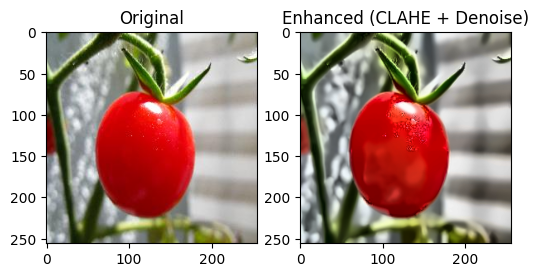

In [ ]:
# ===============================================================
# 2️⃣ IMAGE ENHANCEMENT (CLAHE + DENOISE)
# ===============================================================
def enhance_image(img):
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8))
    cl = clahe.apply(l)
    limg = cv2.merge((cl,a,b))
    enhanced = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)
    denoised = cv2.fastNlMeansDenoisingColored(enhanced, None, 10, 10, 7, 21)
    return denoised

# Contoh hasil enhancement
sample_path = glob(os.path.join(base_dir, "*/*.jpg"))[0]
img_ori = cv2.cvtColor(cv2.imread(sample_path), cv2.COLOR_BGR2RGB)
img_enh = enhance_image(img_ori)

plt.figure(figsize=(6,3))
plt.subplot(1,2,1)
plt.imshow(img_ori)
plt.title("Original")
plt.subplot(1,2,2)
plt.imshow(img_enh)
plt.title("Enhanced (CLAHE + Denoise)")
plt.show()

In [ ]:
# ===============================================================
# 3️⃣ BUAT DATASET ENHANCED
# ===============================================================

base_dir = "/content/plantvillage/plantvillage/PlantVillage"
classes = sorted(os.listdir(base_dir))
print("Kelas terdeteksi:", classes)
print("Jumlah kelas:", len(classes))

enh_dir = "/content/PlantVillage_enh"
os.makedirs(enh_dir, exist_ok=True)

for cls in classes:
    src_dir = os.path.join(base_dir, cls)
    dst_dir = os.path.join(enh_dir, cls)
    os.makedirs(dst_dir, exist_ok=True)

    # Include both .jpg and .JPG files
    imgs = glob(os.path.join(src_dir, "*.jpg")) + glob(os.path.join(src_dir, "*.JPG"))
    print(f"📂 {cls} -> ditemukan {len(imgs)} gambar")

    if len(imgs) == 0:
        print(f"⚠️  Tidak ada gambar pada kelas {cls}, dilewati.")
        continue

    for img_path in imgs[:700]:  # ambil max 700 gambar per kelas
        img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
        enh = enhance_image(img)
        save_path = os.path.join(dst_dir, os.path.basename(img_path))
        cv2.imwrite(save_path, cv2.cvtColor(enh, cv2.COLOR_RGB2BGR))

print("✅ Enhancement selesai dan tersimpan di:", enh_dir)

Kelas terdeteksi: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']
Jumlah kelas: 15
📂 Pepper__bell___Bacterial_spot -> ditemukan 997 gambar
📂 Pepper__bell___healthy -> ditemukan 1477 gambar
📂 Potato___Early_blight -> ditemukan 1000 gambar
📂 Potato___Late_blight -> ditemukan 1000 gambar
📂 Potato___healthy -> ditemukan 152 gambar
📂 Tomato_Bacterial_spot -> ditemukan 2127 gambar
📂 Tomato_Early_blight -> ditemukan 1000 gambar
📂 Tomato_Late_blight -> ditemukan 1908 gambar
📂 Tomato_Leaf_Mold -> ditemukan 952 gambar
📂 Tomato_Septoria_leaf_spot -> ditemukan 1771 gambar
📂 Tomato_Spider_mites_Two_spotted_spider_mite -> ditemukan 1676 gambar
📂 

In [ ]:
# ===============================================================
# 4️⃣ DATA GENERATOR (ORI & ENHANCED)
# ===============================================================
datagen = ImageDataGenerator(validation_split=0.2, rescale=1./255)

train_ori = datagen.flow_from_directory(base_dir, target_size=(150,150), batch_size=32, subset='training')
val_ori = datagen.flow_from_directory(base_dir, target_size=(150,150), batch_size=32, subset='validation')

train_enh = datagen.flow_from_directory(enh_dir, target_size=(150,150), batch_size=32, subset='training')
val_enh = datagen.flow_from_directory(enh_dir, target_size=(150,150), batch_size=32, subset='validation')

Found 16516 images belonging to 15 classes.
Found 4122 images belonging to 15 classes.
Found 7701 images belonging to 15 classes.
Found 1924 images belonging to 15 classes.


In [ ]:
# ===============================================================
# 5️⃣ MODEL RESNET50 (TRANSFER LEARNING)
# ===============================================================
def build_model():
    base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(150,150,3))
    for layer in base_model.layers[:-10]:
        layer.trainable = False
    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(len(classes), activation='softmax')
    ])
    model.compile(optimizer=optimizers.Adam(1e-4),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

In [ ]:
# ===============================================================
# 6️⃣ EKSPERIMEN 1 (ORIGINAL DATA)
# ===============================================================
model_ori = build_model()
history_ori = model_ori.fit(train_ori, validation_data=val_ori, epochs=50)
model_ori.save("model_ori.h5")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


517/517 ━━━━━━━━━━━━━━━━━━━━ 69s 99ms/step - accuracy: 0.4181 - loss: 1.8210 - val_accuracy: 0.3430 - val_loss: 1.9520
Epoch 2/50
517/517 ━━━━━━━━━━━━━━━━━━━━ 36s 69ms/step - accuracy: 0.6547 - loss: 1.0508 - val_accuracy: 0.4993 - val_loss: 1.7600
Epoch 3/50
517/517 ━━━━━━━━━━━━━━━━━━━━ 40s 77ms/step - accuracy: 0.7101 - loss: 0.8770 - val_accuracy: 0.6606 - val_loss: 1.0569
Epoch 4/50
517/517 ━━━━━━━━━━━━━━━━━━━━ 36s 70ms/step - accuracy: 0.7398 - loss: 0.7815 - val_accuracy: 0.7043 - val_loss: 0.8829
Epoch 5/50
517/517 ━━━━━━━━━━━━━━━━━━━━ 36s 69ms/step - accuracy: 0.7612 - loss: 0.7091 - val_accuracy: 0.7135 - val_loss: 0.8892
Epoch 6/50
517/517 ━━━━━━━━━━━━━━━━━━━━ 40s 77ms/step - accuracy: 0.7891 - loss: 0.6372 - val_accuracy: 0.7055 - val_loss: 0.8672
Epoch 7/50
517/517 ━━━━━━━━━━━━━━━━━━━━ 36s 69ms/step - accuracy: 0.7950 - loss: 0.6140 - val_accuracy: 0.7545 - val_loss: 0.7128
Epoch 8/50
517/517 ━━━━━━━━━━━━━━━━━━━━ 36s 69ms/step - accuracy: 0.8124 - loss: 0.5569 - val_accurac

In [ ]:
# ===============================================================
# 7️⃣ EKSPERIMEN 2 (ENHANCED DATA)
# ===============================================================
model_enh = build_model()
history_enh = model_enh.fit(train_enh, validation_data=val_enh, epochs=50)
model_enh.save("model_enh.h5")

Epoch 1/50
241/241 ━━━━━━━━━━━━━━━━━━━━ 45s 133ms/step - accuracy: 0.3333 - loss: 2.0442 - val_accuracy: 0.1694 - val_loss: 2.9894
Epoch 2/50
241/241 ━━━━━━━━━━━━━━━━━━━━ 17s 71ms/step - accuracy: 0.6216 - loss: 1.1794 - val_accuracy: 0.6528 - val_loss: 1.0955
Epoch 3/50
241/241 ━━━━━━━━━━━━━━━━━━━━ 17s 71ms/step - accuracy: 0.6914 - loss: 0.9516 - val_accuracy: 0.6367 - val_loss: 1.0856
Epoch 4/50
241/241 ━━━━━━━━━━━━━━━━━━━━ 17s 72ms/step - accuracy: 0.7323 - loss: 0.8280 - val_accuracy: 0.6949 - val_loss: 0.9435
Epoch 5/50
241/241 ━━━━━━━━━━━━━━━━━━━━ 17s 70ms/step - accuracy: 0.7541 - loss: 0.7281 - val_accuracy: 0.6928 - val_loss: 0.9211
Epoch 6/50
241/241 ━━━━━━━━━━━━━━━━━━━━ 18s 74ms/step - accuracy: 0.7874 - loss: 0.6491 - val_accuracy: 0.6325 - val_loss: 1.1441
Epoch 7/50
241/241 ━━━━━━━━━━━━━━━━━━━━ 17s 71ms/step - accuracy: 0.8011 - loss: 0.5920 - val_accuracy: 0.7162 - val_loss: 0.8820
Epoch 8/50
241/241 ━━━━━━━━━━━━━━━━━━━━ 17s 71ms/step - accuracy: 0.8414 - loss: 0.4832 -


🎯 Akurasi Validasi Original : 77.92%
🌿 Akurasi Validasi Enhanced : 68.66%


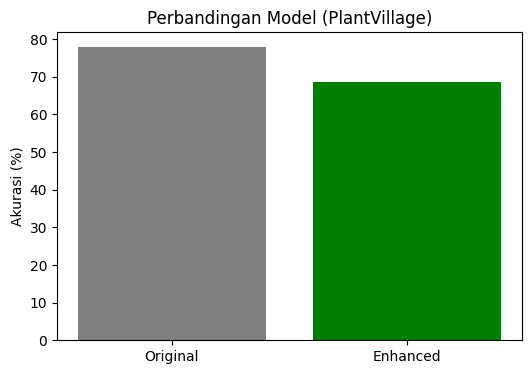

In [ ]:
# ===============================================================
# 8️⃣ EVALUASI & PERBANDINGAN
# ===============================================================
acc_ori = history_ori.history['val_accuracy'][-1]
acc_enh = history_enh.history['val_accuracy'][-1]

print(f"\n🎯 Akurasi Validasi Original : {acc_ori*100:.2f}%")
print(f"🌿 Akurasi Validasi Enhanced : {acc_enh*100:.2f}%")

plt.figure(figsize=(6,4))
plt.bar(["Original", "Enhanced"], [acc_ori*100, acc_enh*100], color=['gray','green'])
plt.ylabel("Akurasi (%)")
plt.title("Perbandingan Model (PlantVillage)")
plt.show()

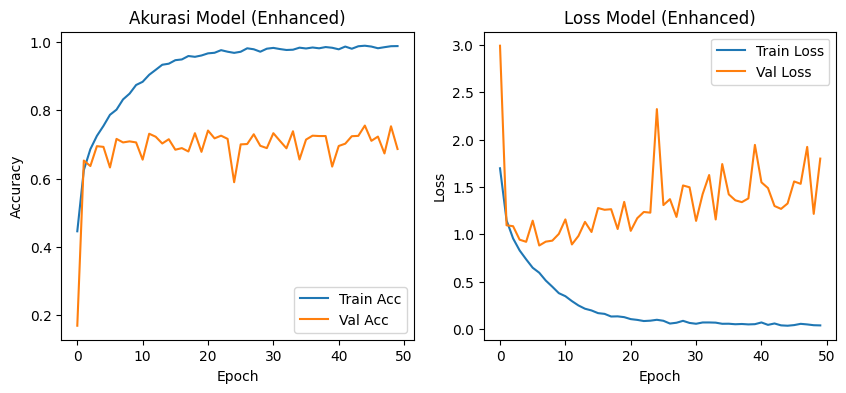

61/61 ━━━━━━━━━━━━━━━━━━━━ 12s 124ms/step


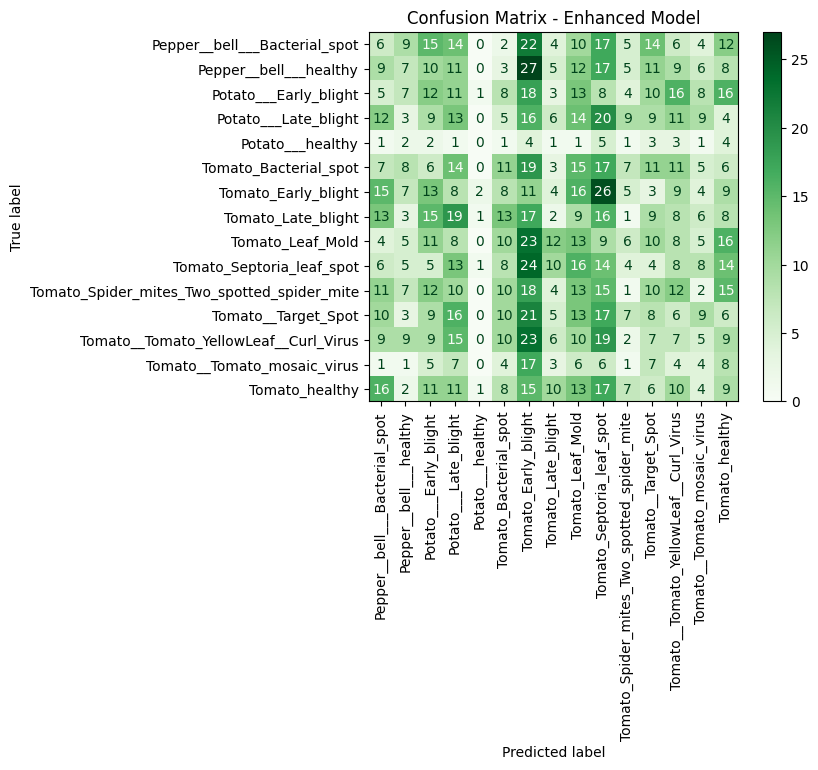


Laporan Klasifikasi (Enhanced Model):

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.05      0.04      0.05       140
                     Pepper__bell___healthy       0.09      0.05      0.06       140
                      Potato___Early_blight       0.08      0.09      0.08       140
                       Potato___Late_blight       0.08      0.09      0.08       140
                           Potato___healthy       0.00      0.00      0.00        30
                      Tomato_Bacterial_spot       0.10      0.08      0.09       140
                        Tomato_Early_blight       0.04      0.08      0.05       140
                         Tomato_Late_blight       0.03      0.01      0.02       140
                           Tomato_Leaf_Mold       0.07      0.09      0.08       140
                  Tomato_Septoria_leaf_spot       0.06      0.10      0.08       140
Tomato_Spider_mites_Two_

In [ ]:
# ===============================================================
# STEP 9 - Evaluasi Model (Grafik & Confusion Matrix)
# ===============================================================
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# --- 1. Plot Akurasi dan Loss
def plot_history(history, title_suffix=""):
    plt.figure(figsize=(10,4))

    # Plot Accuracy
    plt.subplot(1,2,1)
    plt.plot(history.history['accuracy'], label='Train Acc')
    plt.plot(history.history['val_accuracy'], label='Val Acc')
    plt.title(f'Akurasi Model {title_suffix}')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    # Plot Loss
    plt.subplot(1,2,2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title(f'Loss Model {title_suffix}')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.show()

# tampilkan grafik training
plot_history(history_enh, "(Enhanced)")
# kalau mau bandingkan dua model:
# plot_history(history_ori, "(Original)")

# --- 2. Confusion Matrix untuk model enhanced
# Ambil data validasi dan prediksi
val_generator = val_enh  # atau val_ori untuk model original
y_true = val_generator.classes
y_pred = np.argmax(model_enh.predict(val_generator), axis=1)

# --- 3. Buat confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=range(len(classes)))

# --- 4. Tampilkan confusion matrix dengan label lengkap
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
disp.plot(xticks_rotation=90, cmap='Greens')
plt.title("Confusion Matrix - Enhanced Model")
plt.show()

# --- 5. Tambahkan laporan klasifikasi
print("\nLaporan Klasifikasi (Enhanced Model):\n")
print(classification_report(y_true, y_pred, target_names=classes))


1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


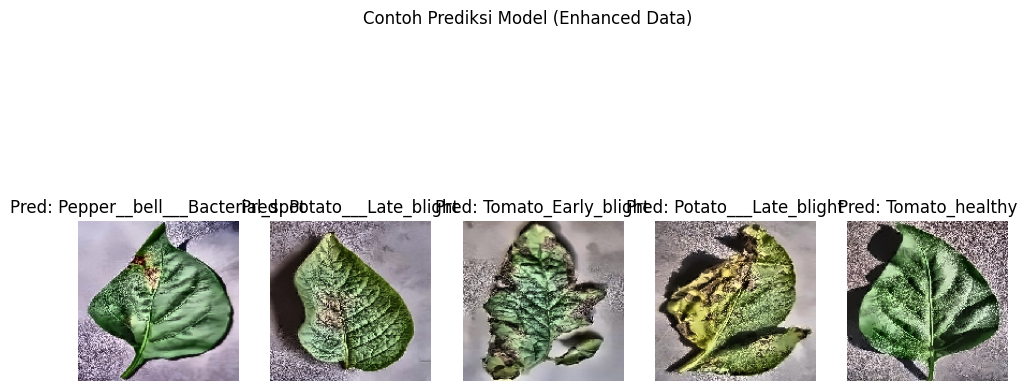

In [ ]:
# ===============================================================
# 🔟 VISUALISASI HASIL PREDIKSI MODEL
# ===============================================================
sample_batch, _ = next(iter(val_enh))
preds = model_enh.predict(sample_batch)
labels = np.argmax(preds, axis=1)

plt.figure(figsize=(12,6))
for i in range(5):
    plt.subplot(1,5,i+1)
    plt.imshow(sample_batch[i])
    plt.title(f"Pred: {classes[labels[i]]}")
    plt.axis('off')
plt.suptitle("Contoh Prediksi Model (Enhanced Data)")
plt.show()

In [ ]:
# ===============================================================
# 1️⃣1️⃣ KESIMPULAN
# ===============================================================
print("\n=== KESIMPULAN TTS ===")
print(f"Akurasi model dengan citra ORIGINAL  : {acc_ori*100:.2f}%")
print(f"Akurasi model dengan citra ENHANCED  : {acc_enh*100:.2f}%")
if acc_enh > acc_ori:
    print("✅ Model dengan preprocessing (CLAHE + Denoise) menunjukkan peningkatan performa.")
else:
    print("⚠️ Model enhanced tidak menunjukkan peningkatan signifikan, mungkin perlu tuning lebih lanjut.")
print("Eksperimen ini menunjukkan bahwa image enhancement dapat membantu CNN dalam mendeteksi penyakit daun secara lebih akurat.")


=== KESIMPULAN TTS ===
Akurasi model dengan citra ORIGINAL  : 77.92%
Akurasi model dengan citra ENHANCED  : 68.66%
⚠️ Model enhanced tidak menunjukkan peningkatan signifikan, mungkin perlu tuning lebih lanjut.
Eksperimen ini menunjukkan bahwa image enhancement dapat membantu CNN dalam mendeteksi penyakit daun secara lebih akurat.
